 # Smart Outcome Predictor

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler



from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor
from sklearn.ensemble import (
    BaggingClassifier,BaggingRegressor,
    AdaBoostClassifier,AdaBoostRegressor,
    VotingClassifier,VotingRegressor,
    StackingClassifier,StackingRegressor
)
from xgboost import XGBClassifier,XGBRegressor
from sklearn.linear_model import LogisticRegression,LinearRegression



from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
from sklearn.metrics import mean_absolute_error,root_mean_squared_error,r2_score

# Conceptual Foundation (Theory)

### 1. What are Ensemble Learning Methods and why are they effective?

Ensemble Learning combines multiple machine learning models to produce a more accurate and reliable prediction than a single model. These methods are effective because they can reduce errors, improve generalization, and increase model performance.

### 2. Explain the difference between Bagging, Boosting, and Voting.

- **Bagging:** Trains multiple models independently on different bootstrap samples and combines their predictions to reduce variance.
- **Boosting:** Trains models sequentially, where each new model focuses on correcting the errors of previous models.
- **Voting:** Combines predictions from multiple different models using majority voting (hard voting) or average predicted probabilities (soft voting).

### 3. What is Bias–Variance Trade-off, and how do ensemble methods address it?

The Bias–Variance Trade-off describes the balance between underfitting (high bias) and overfitting (high variance). Bagging helps reduce variance, while Boosting can reduce bias by improving weak learners; the goal is to improve generalization on unseen data.

### 4. Explain Voting Classifier and Stacking Ensemble.

A **Voting Classifier** combines predictions from multiple classification models using hard voting or soft voting. A **Stacking Ensemble** uses the predictions of base models as input features for a meta-model, which learns how to combine their predictions effectively.

### 5. Compare AdaBoost and XGBoost conceptually.

**AdaBoost** builds models sequentially by assigning greater weight to previously misclassified training samples. **XGBoost** is an optimized gradient boosting algorithm that uses gradient-based optimization, regularization, and efficient computation to improve predictive performance and control overfitting.

In [2]:
# file path
base_path = Path().cwd().parent
model_path = base_path/"model"
output_path = base_path/"outputs"
data_path = base_path/"data"/"Smart_Outcome_Predictor.csv"

In [3]:
# Load data and baseic info
df = pd.read_csv(data_path)
print("*-*"*10)
print("Shape:",df.shape)
print("*-*"*10)
print("\n Top 5 rows:")
display(df.head(5))
print("\ninfo:")
print(df.info())

*-**-**-**-**-**-**-**-**-**-*
Shape: (5200, 19)
*-**-**-**-**-**-**-**-**-**-*

 Top 5 rows:


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4



info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             5200 non-null   int64  
 1   age                    5200 non-null   int64  
 2   country_region         5200 non-null   object 
 3   device_type            5200 non-null   object 
 4   education_background   5200 non-null   object 
 5   course_level           5200 non-null   object 
 6   course_category        5200 non-null   object 
 7   course_start_date      5200 non-null   object 
 8   week_of_year           5200 non-null   int64  
 9   sessions               5200 non-null   int64  
 10  time_spent_hours       5088 non-null   float64
 11  videos_watched         5200 non-null   int64  
 12  quiz_attempts          5200 non-null   int64  
 13  assignments_submitted  5200 non-null   int64  
 14  forum_posts            5200 non-null   int64  
 1

In [4]:
# stat decription
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
student_id,5200.0,702600.500000,1501.255031,700001.000,701300.75000,702600.500,703900.250,705200.0
age,5200.0,24.339615,5.578864,16.000,20.00000,24.000,28.000,45.0
week_of_year,5200.0,26.621538,15.007731,1.000,14.00000,27.000,40.000,52.0
sessions,5200.0,19.121923,10.726708,1.000,11.00000,17.000,25.000,94.0
time_spent_hours,5088.0,18.216156,10.734114,0.600,10.30000,16.100,23.800,76.8
videos_watched,5200.0,25.852885,17.720493,0.000,13.00000,23.000,35.000,158.0
quiz_attempts,5200.0,6.995769,2.568017,0.000,5.00000,7.000,9.000,20.0
assignments_submitted,5200.0,3.835769,1.951802,0.000,2.00000,4.000,5.000,12.0
forum_posts,5200.0,1.585577,1.270640,0.000,1.00000,1.000,2.000,8.0
avg_quiz_score,5119.0,66.842626,13.813992,0.000,57.50000,66.900,76.200,100.0


In [5]:
# Null value count and it's %
isnull_in_df = df.isnull().sum()
isnull_pr = round(df.isnull().mean()*100,2)

isnull_df = pd.DataFrame({
    "columns":isnull_in_df.index,
    "isnull_count":isnull_in_df.values,
    "isnull_%":isnull_pr.values})

display(isnull_df[isnull_df["isnull_count"]>0])

,columns,isnull_count,isnull_%
10,time_spent_hours,112,2.15
15,avg_quiz_score,81,1.56
16,attendance_rate,80,1.54


In [6]:
# duplicate values in df
df.duplicated().sum()

0

In [7]:
# Identify features and target variables for both tasks.
X = df.drop(columns = ["student_id","final_score","completion_status"])
y_cf = df["completion_status"]
y_rg = df["final_score"]

In [8]:
# create coruse durection in days
c_date = pd.to_datetime(df["course_start_date"],errors="coerce")

# create numrical columns
last_c_data = c_date.max()

X["couse_durection_day"] = (last_c_data - c_date).dt.days
X=X.drop(columns=["course_start_date"])

print("\nupdated Shape:",X.shape)
print("")
display(X.head())


updated Shape: (5200, 16)



,age,country_region,device_type,education_background,course_level,course_category,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,couse_durection_day
0,32,Europe,Laptop,Undergrad,Intermediate,Business,12,1,7.6,1,6,1,1,53.3,0.655,287
1,17,Europe,Laptop,Undergrad,Intermediate,Programming,34,16,27.2,6,4,7,1,51.5,1.000,130
2,25,Europe,Mobile,Graduate,Advanced,Programming,39,6,7.1,16,2,2,0,62.2,0.810,93
3,26,Asia,Mobile,Undergrad,Beginner,Design,10,34,22.1,57,9,6,0,59.3,0.875,296
4,26,Asia,Tablet,WorkingPro,Advanced,Business,12,22,32.3,41,9,2,0,65.1,0.814,284


In [9]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5200 entries, 0 to 5199
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    5200 non-null   int64  
 1   country_region         5200 non-null   object 
 2   device_type            5200 non-null   object 
 3   education_background   5200 non-null   object 
 4   course_level           5200 non-null   object 
 5   course_category        5200 non-null   object 
 6   week_of_year           5200 non-null   int64  
 7   sessions               5200 non-null   int64  
 8   time_spent_hours       5088 non-null   float64
 9   videos_watched         5200 non-null   int64  
 10  quiz_attempts          5200 non-null   int64  
 11  assignments_submitted  5200 non-null   int64  
 12  forum_posts            5200 non-null   int64  
 13  avg_quiz_score         5119 non-null   float64
 14  attendance_rate        5120 non-null   float64
 15  cous

In [10]:
# select a num and cat columns
num_col = X.select_dtypes(include=["int64","float64"]).columns.tolist()

cat_col = X.select_dtypes(include = ["object"]).columns.tolist()

print("\nNumerical Columns:")
print(num_col)

print("\nCategorcal Columns:")
print(cat_col)

display(df.head())


Numerical Columns:
['age', 'week_of_year', 'sessions', 'time_spent_hours', 'videos_watched', 'quiz_attempts', 'assignments_submitted', 'forum_posts', 'avg_quiz_score', 'attendance_rate', 'couse_durection_day']

Categorcal Columns:
['country_region', 'device_type', 'education_background', 'course_level', 'course_category']


,student_id,age,country_region,device_type,education_background,course_level,course_category,course_start_date,week_of_year,sessions,time_spent_hours,videos_watched,quiz_attempts,assignments_submitted,forum_posts,avg_quiz_score,attendance_rate,completion_status,final_score
0,700001,32,Europe,Laptop,Undergrad,Intermediate,Business,2024-03-18,12,1,7.6,1,6,1,1,53.3,0.655,0,49.8
1,700002,17,Europe,Laptop,Undergrad,Intermediate,Programming,2024-08-22,34,16,27.2,6,4,7,1,51.5,1.000,1,84.0
2,700003,25,Europe,Mobile,Graduate,Advanced,Programming,2024-09-28,39,6,7.1,16,2,2,0,62.2,0.810,0,62.5
3,700004,26,Asia,Mobile,Undergrad,Beginner,Design,2024-03-09,10,34,22.1,57,9,6,0,59.3,0.875,1,89.5
4,700005,26,Asia,Tablet,WorkingPro,Advanced,Business,2024-03-21,12,22,32.3,41,9,2,0,65.1,0.814,0,67.4


In [11]:
# train test splite for regrection
X_train_r,X_test_r,y_train_r,y_test_r = train_test_split(X,y_rg,test_size=0.2,random_state=42)

# train test split for calcefation
X_train_c,X_test_c,y_train_c,y_test_c = train_test_split(X,y_cf,test_size=0.2,random_state=42,stratify=y_cf)

print("Regrection Train and test shape")
print("X_train:",X_train_r.shape)
print("X_test:",X_test_r.shape)

print("\nclassifiction Train and test shape")
print("X_train:",X_train_c.shape)
print("X_test:",X_test_c.shape)

Regrection Train and test shape
X_train: (4160, 16)
X_test: (1040, 16)

classifiction Train and test shape
X_train: (4160, 16)
X_test: (1040, 16)


completion_status
0    3248
1    1952
Name: count, dtype: int64


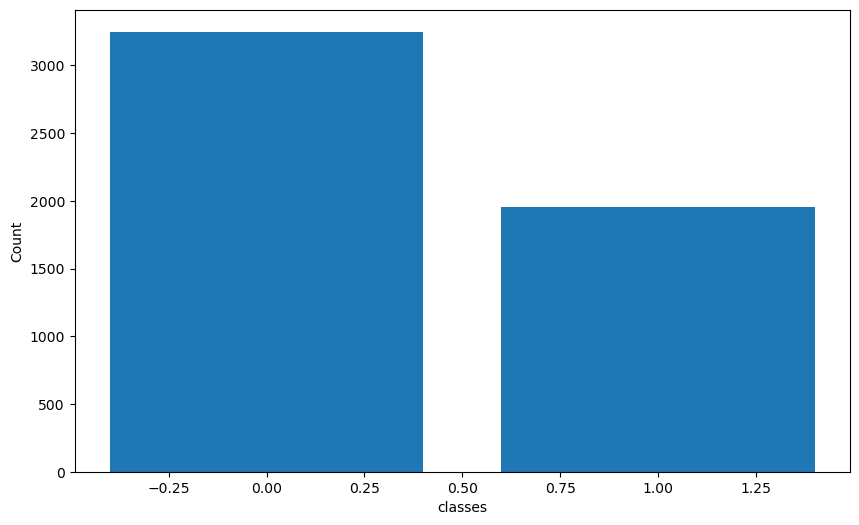

In [12]:
# for classification clases distribution
print(y_cf.value_counts())

plt.figure(figsize=(10,6))
plt.bar(y_cf.value_counts().index,y_cf.value_counts())
plt.xlabel("classes")
plt.ylabel("Count")
plt.savefig(output_path/"classes_distrbution.png")
plt.show()

In [13]:
# def of model evalution
# regrestion
def evalution(ty,name,model,X_train,X_test,y_train,y_test):
    if ty == "rg":
        r_df_rg = []

        model.fit(X_train,y_train)
        y_pred=model.predict(X_test)
    
        r_df_rg.append({
        "model":name,
        "MAE":mean_absolute_error(y_test,y_pred),
        "RMSE":root_mean_squared_error(y_test,y_pred),
        "R2 Socre":r2_score(y_test,y_pred),
        })

        return r_df_rg
    else:
        r_df_cf = []

        model.fit(X_train,y_train)
        y_pred=model.predict(X_test)

        y_prob = (
            model.predict_proba(X_test)[:, 1]
            if hasattr(model, "predict_proba")
            else y_pred
        )
        r_df_cf.append({
        "model":name,
        "Accuracy":accuracy_score(y_test,y_pred),
        "precision":precision_score(y_test,y_pred,zero_division=0),
        "Recall":recall_score(y_test,y_pred,zero_division=0),
        "F1 Score":f1_score(y_test,y_pred,zero_division=0),
        "ROC_AUC Score":roc_auc_score(y_test,y_prob)
        })

        return r_df_cf

In [14]:
# preprocesion piplune

num_pipe = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

# Combined preprocessing
preprocessor = ColumnTransformer([
    ("num",num_pipe,num_col),
    ("cat",cat_pipe,cat_col)
])

# Bagging (Bootstrap Aggregating)

In [15]:
# Bagging Classifier
base_cf = Pipeline([
    ("preprocessor",preprocessor),
    ("model",DecisionTreeClassifier(max_depth=4,random_state=42))
])

bagging_cf = Pipeline([
    ("preprocessor",preprocessor),
    ("model",BaggingClassifier(
        estimator=DecisionTreeClassifier(max_depth=4),
        n_estimators=50,
        max_samples=0.8,
        n_jobs=-1,
        random_state=42))
])

base_cf_result = evalution(
    "cf","Decision Tree",base_cf,
    X_train_c,X_test_c,y_train_c,y_test_c
)

bagging_cf_result = evalution(
    "cf","Bagging Classifier",bagging_cf,
    X_train_c,X_test_c,y_train_c,y_test_c
)

cf_results= pd.DataFrame(base_cf_result+bagging_cf_result)

display(cf_results.round(2))

,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
0,Decision Tree,0.71,0.63,0.51,0.56,0.75
1,Bagging Classifier,0.72,0.67,0.53,0.59,0.78


In [16]:
# Bagging Regressor
base_rg = Pipeline([
    ("preprocessor",preprocessor),
    ("model",DecisionTreeRegressor(max_depth=4,random_state=42))
])

bagging_rg = Pipeline([
    ("preprocessor",preprocessor),
    ("model",BaggingRegressor(
        estimator=DecisionTreeRegressor(max_depth=4),
        n_estimators=50,
        max_samples=0.8,
        n_jobs=-1,
        random_state=42))
])

base_rg_result = evalution(
    "rg","Decision Tree",base_rg,
    X_train_r,X_test_r,y_train_r,y_test_r
)

bagging_rg_result = evalution(
    "rg","Bagging Regressor",bagging_rg,
    X_train_r,X_test_r,y_train_r,y_test_r
)


rg_result = pd.DataFrame(base_rg_result+bagging_rg_result).round(2)
display(rg_result)

,model,MAE,RMSE,R2 Socre
0,Decision Tree,9.03,11.11,0.34
1,Bagging Regressor,8.42,10.43,0.42


# Boosting Algorithms

 # AdaBoost

In [17]:
# Adaboost Classifier
ada_cf = Pipeline([
    ("preprocessor",preprocessor),
    ("model",AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=3),
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    ))
])

ada_cf_result = evalution(
    "cf","AdaBoost Classifier",ada_cf,
    X_train_c,X_test_c,y_train_c,y_test_c
)

display(pd.DataFrame(ada_cf_result).round(2))

,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
0,AdaBoost Classifier,0.72,0.64,0.58,0.61,0.77


In [18]:
# Adaboost Regressor
ada_rg = Pipeline([
    ("preprocessor",preprocessor),
    ("model",AdaBoostRegressor(
        estimator=DecisionTreeRegressor(max_depth=3),
        n_estimators=50,
        learning_rate=1.0,
        random_state=42
    ))
])

ada_rg_result = evalution(
    "rg","AdaBoost Regressor",ada_rg,
    X_train_r,X_test_r,y_train_r,y_test_r
)

display(pd.DataFrame(ada_rg_result).round(2))

,model,MAE,RMSE,R2 Socre
0,AdaBoost Regressor,8.6,10.54,0.41


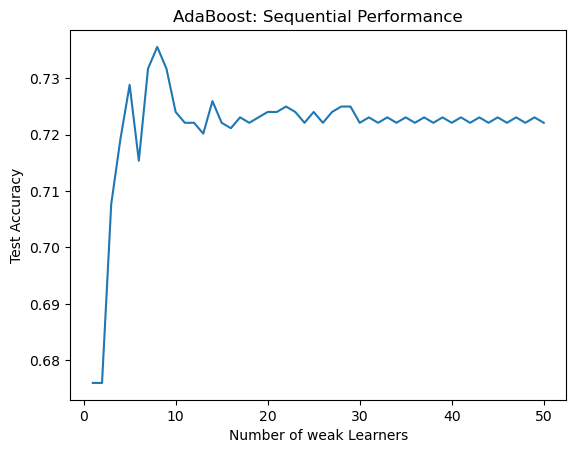

In [19]:
# Analyze how weak learners improve sequentially
ada_model = ada_cf.named_steps["model"]
X_test_processed = ada_cf.named_steps["preprocessor"].transform(X_test_c)

staged_accuracy = [
    accuracy_score(y_test_c,pred)
    for pred in ada_model.staged_predict(X_test_processed)
]

plt.plot(range(1,len(staged_accuracy)+1),staged_accuracy)
plt.xlabel("Number of weak Learners")
plt.ylabel("Test Accuracy")
plt.title("AdaBoost: Sequential Performance")
plt.show()

 # XGBoost

In [20]:
# XGBoost Classifier
xgb_cf = Pipeline([
    ("preprocessor",preprocessor),
    ("model",XGBClassifier(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

xgb_cf_result = evalution(
    "cf","XGBoost Classifier",xgb_cf,
    X_train_c,X_test_c,y_train_c,y_test_c
)

display(pd.DataFrame(xgb_cf_result).round(2))

,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
0,XGBoost Classifier,0.73,0.66,0.57,0.61,0.78


In [21]:
# XGBoost Regressor
xgb_rg = Pipeline([
    ("preprocessor",preprocessor),
    ("model",XGBRegressor(
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1
    ))
])

xgb_rg_result = evalution(
    "rg","XGBoost Regressor",xgb_rg,
    X_train_r,X_test_r,y_train_r,y_test_r
)

display(pd.DataFrame(xgb_rg_result).round(2))

,model,MAE,RMSE,R2 Socre
0,XGBoost Regressor,7.93,9.88,0.48


 # Compare Bagging, AdaBoost and XGBoost

In [22]:
# Classification comparison
cf_comparison = pd.DataFrame(
    base_cf_result+bagging_cf_result+ada_cf_result+xgb_cf_result
)

display(cf_comparison.sort_values("F1 Score",ascending=False).round(3))

,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
3,XGBoost Classifier,0.729,0.661,0.569,0.612,0.781
2,AdaBoost Classifier,0.719,0.638,0.582,0.609,0.772
1,Bagging Classifier,0.724,0.666,0.531,0.591,0.776
0,Decision Tree,0.706,0.635,0.508,0.564,0.753


In [23]:
# Regression comparison
rg_comparison = pd.DataFrame(
    base_rg_result+bagging_rg_result+ada_rg_result+xgb_rg_result
)

display(rg_comparison.sort_values("RMSE").round(3))

,model,MAE,RMSE,R2 Socre
3,XGBoost Regressor,7.933,9.882,0.477
1,Bagging Regressor,8.419,10.427,0.418
2,AdaBoost Regressor,8.602,10.542,0.405
0,Decision Tree,9.031,11.107,0.340


# Voting & Stacking Ensembles

In [24]:
# Voting Classifier
voting_hard = VotingClassifier(
    estimators=[
        ("dt",base_cf),
        ("ada",ada_cf),
        ("xgb",xgb_cf)
    ],
    voting="hard",
    n_jobs=-1
)

hard_result = evalution(
    "cf","Hard Voting",voting_hard,
    X_train_c,X_test_c,y_train_c,y_test_c
)

voting_soft = VotingClassifier(
    estimators=[
        ("dt",base_cf),
        ("ada",ada_cf),
        ("xgb",xgb_cf)
    ],
    voting="soft",
    n_jobs=-1
)

soft_result = evalution(
    "cf","Soft Voting",voting_soft,
    X_train_c,X_test_c,y_train_c,y_test_c
)

display(pd.DataFrame(hard_result+soft_result).round(3))

,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
0,Hard Voting,0.725,0.655,0.564,0.606,0.693
1,Soft Voting,0.727,0.663,0.554,0.603,0.781


In [25]:
# Stack classifier
stack_cf = StackingClassifier(
    estimators=[
        ("dt",base_cf),
        ("ada",ada_cf),
        ("xgb",xgb_cf)
    ],
    final_estimator=LogisticRegression(),
    cv=5,
    n_jobs=-1
)

stack_cf_result = evalution(
    "cf", "Stacking Classifier", stack_cf,
    X_train_c, X_test_c, y_train_c, y_test_c
)

display(pd.DataFrame(stack_cf_result).round(4))

,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
0,Stacking Classifier,0.7317,0.6785,0.541,0.602,0.7836


In [26]:
# Stack Regessor
stack_rg = StackingRegressor(
    estimators=[
        ("dt",base_rg),
        ("ada",ada_rg),
        ("xgb",xgb_rg)
    ],
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1
)

stack_rg_result = evalution(
    "rg", "Stacking Regressor", stack_rg,
    X_train_r, X_test_r, y_train_r, y_test_r
)

display(pd.DataFrame(stack_rg_result).round(4))

,model,MAE,RMSE,R2 Socre
0,Stacking Regressor,7.9338,9.8451,0.4812


# Model Evaluation & Comparison

In [27]:
# classification comparison
cf_comparison = pd.DataFrame(
    base_cf_result+bagging_cf_result+
    ada_cf_result+xgb_cf_result+
    hard_result+soft_result+stack_cf_result
)
display(cf_comparison.round(3))

,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
0,Decision Tree,0.706,0.635,0.508,0.564,0.753
1,Bagging Classifier,0.724,0.666,0.531,0.591,0.776
2,AdaBoost Classifier,0.719,0.638,0.582,0.609,0.772
3,XGBoost Classifier,0.729,0.661,0.569,0.612,0.781
4,Hard Voting,0.725,0.655,0.564,0.606,0.693
5,Soft Voting,0.727,0.663,0.554,0.603,0.781
6,Stacking Classifier,0.732,0.678,0.541,0.602,0.784


In [28]:
best_cf = cf_comparison.sort_values(
    "F1 Score",ascending=False
).iloc[0]

print("Bast Clasification Model:",best_cf["model"])
display(best_cf.to_frame().T)

Bast Clasification Model: XGBoost Classifier


,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
3,XGBoost Classifier,0.728846,0.660714,0.569231,0.61157,0.780927


In [29]:
# Regressoion comparison
rg_comparison = pd.DataFrame(
    base_rg_result+bagging_rg_result+
    ada_rg_result+xgb_rg_result+
    stack_rg_result
)
display(rg_comparison.round(3))

,model,MAE,RMSE,R2 Socre
0,Decision Tree,9.031,11.107,0.340
1,Bagging Regressor,8.419,10.427,0.418
2,AdaBoost Regressor,8.602,10.542,0.405
3,XGBoost Regressor,7.933,9.882,0.477
4,Stacking Regressor,7.934,9.845,0.481


In [30]:
best_rg = rg_comparison.sort_values(
    "RMSE"
).iloc[0]

print("Bast Regression Model:",best_rg["model"])
display(best_rg.to_frame().T)

Bast Regression Model: Stacking Regressor


,model,MAE,RMSE,R2 Socre
4,Stacking Regressor,7.933769,9.845063,0.481238


# Final Analysis & Reporting

In [31]:
# XGBoost Classifier - hyperparmeter Tuning
cf_grid = {
    "model__n_estimators":[100,200,300],
    "model__max_depth":[3,4,5,6],
    "model__learning_rate":[0.03,0.1,0.05,0.2],
    "model__subsample":[0.8,1.0],
    "model__colsample_bytree":[0.8,1.0]
}

cf_search = GridSearchCV(
    xgb_cf,
    cf_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

cf_search.fit(X_train_c,y_train_c)

best_xgb_cf = cf_search.best_estimator_

print("Best Parameters:",cf_search.best_params_)
print("Best CV F1 score:",round(cf_search.best_score_,3))

Fitting 5 folds for each of 192 candidates, totalling 960 fits
Best Parameters: {'model__colsample_bytree': 0.8, 'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200, 'model__subsample': 1.0}
Best CV F1 score: 0.594


In [32]:
# Stacking Regerssor - Hyperparmeter Tuning
rg_grid = {
    "xgb__model__n_estimators": [100, 200],
    "xgb__model__max_depth": [3, 4],
    "xgb__model__learning_rate": [0.03, 0.1],
    "ada__model__n_estimators": [50, 100]
}

rg_search = GridSearchCV(
    stack_rg,
    rg_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

rg_search.fit(X_train_r,y_train_r)
best_stack_rg = rg_search.best_estimator_
print("Best Parameters:", rg_search.best_params_)
print("Best CV RMSE:", round(-rg_search.best_score_, 3))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters: {'ada__model__n_estimators': 100, 'xgb__model__learning_rate': 0.03, 'xgb__model__max_depth': 3, 'xgb__model__n_estimators': 200}
Best CV RMSE: 9.818


In [33]:

tuned_cf_result = evalution(
    "cf", "Tuned XGBoost", best_xgb_cf,
    X_train_c, X_test_c, y_train_c, y_test_c
)

# Tuned Regression Model
tuned_rg_result = evalution(
    "rg", "Tuned Stacking", best_stack_rg,
    X_train_r, X_test_r, y_train_r, y_test_r
)

display(pd.DataFrame(tuned_cf_result).round(4))
display(pd.DataFrame(tuned_rg_result).round(4))

,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
0,Tuned XGBoost,0.7375,0.6736,0.5821,0.6245,0.7855


,model,MAE,RMSE,R2 Socre
0,Tuned Stacking,7.8775,9.8364,0.4822


1. Impact of Bagging vs Boosting

Bagging trains multiple models independently on different bootstrap samples and combines their predictions. It mainly helps reduce variance and improve model stability.

Boosting trains models sequentially, where subsequent learners focus on correcting previous errors. It can improve predictive performance by learning complex patterns.

In this project, Bagging, AdaBoost, and XGBoost were evaluated for student course completion and final score prediction.

2. AdaBoost vs XGBoost

AdaBoost adjusts sample weights to focus more on incorrectly predicted observations. XGBoost uses gradient-based optimization and regularization to build powerful tree-based models.

XGBoost achieved an accuracy of 72.88% and a ROC-AUC score of 0.7809 in the current classification evaluation. Its final performance will be compared with AdaBoost after hyperparameter tuning.

3. Advantages of Voting and Stacking

Voting: Combines predictions from multiple classifiers. Hard voting uses majority voting, while soft voting combines predicted class probabilities.

Stacking: Uses a meta-learner to combine predictions from multiple base models. It can learn how to use the strengths of different models for classification and regression.

4. Best Models and Business Interpretation

The current best classification model is XGBoost Classifier, with an accuracy of 72.88%, F1-score of 0.6116, and ROC-AUC of 0.7809.

The current best regression model is Stacking Regressor, with MAE of 7.93, RMSE of 9.85, and R² of 0.4812.

The classification model can help identify students who may need additional support to complete their courses. The regression model estimates final performance scores and may help instructors plan timely interventions.

These predictions should support educational decisions rather than replace human judgment.

5. Final Recommendation

XGBoost Classifier and Stacking Regressor are the current leading models based on the reported evaluation results. Final deployment decisions will be made after hyperparameter tuning and evaluation on held-out test data.

The completed project will include the Jupyter Notebook, evaluation tables, labelled plots, exported models, a working Streamlit application, and project documentation.

In [48]:
rg_comparison = pd.DataFrame(
    base_rg_result+bagging_rg_result+
    ada_rg_result+xgb_rg_result+
    stack_rg_result+tuned_rg_result
)
display(rg_comparison.round(3))

rg_comparison.to_csv(output_path/"regression_results.csv",index=False)

,model,MAE,RMSE,R2 Socre
0,Decision Tree,9.031,11.107,0.340
1,Bagging Regressor,8.419,10.427,0.418
2,AdaBoost Regressor,8.602,10.542,0.405
3,XGBoost Regressor,7.933,9.882,0.477
4,Stacking Regressor,7.934,9.845,0.481
5,Tuned Stacking,7.877,9.836,0.482


In [49]:
cf_comparison = pd.DataFrame(
    base_cf_result+bagging_cf_result+
    ada_cf_result+xgb_cf_result+
    hard_result+soft_result+stack_cf_result+tuned_cf_result
)
display(cf_comparison.round(3))

cf_comparison.to_csv(output_path/"classification_results.csv",index=False)

,model,Accuracy,precision,Recall,F1 Score,ROC_AUC Score
0,Decision Tree,0.706,0.635,0.508,0.564,0.753
1,Bagging Classifier,0.724,0.666,0.531,0.591,0.776
2,AdaBoost Classifier,0.719,0.638,0.582,0.609,0.772
3,XGBoost Classifier,0.729,0.661,0.569,0.612,0.781
4,Hard Voting,0.725,0.655,0.564,0.606,0.693
5,Soft Voting,0.727,0.663,0.554,0.603,0.781
6,Stacking Classifier,0.732,0.678,0.541,0.602,0.784
7,Tuned XGBoost,0.738,0.674,0.582,0.624,0.786


In [50]:
joblib.dump(best_xgb_cf,model_path/"best_classifiction_model.pkl")
joblib.dump(best_stack_rg,model_path/"best_regression_model.pkl")

['C:\\Users\\MAYUR MAKVANA\\OneDrive\\Desktop\\Works\\projectrnw\\Supervished Learning 12-09-2026\\PR 5\\model\\best_regression_model.pkl']

In [51]:
schema = {}

for col in X_train_c.columns:
    if pd.api.types.is_numeric_dtype(X_train_c[col]):
        values = X_train_c[col].dropna()

        schema[col] = {
        "type":"numeric",
        "default":float(values.median()) if len(values) else 0.0,
        "min":float(values.min()) if len(values) else 0.0,
        "max":float(values.max()) if len(values) else 100.0
        }
    else:
        values = X_train_c[col].dropna().astype(str)
        choices = sorted(values.unique().tolist())
        mode = values.mode()

        schema[col] = {
        "type":"categorical",
        "default":str(mode.iloc[0]) if not mode.empty else (
        choices[0] if choices else "Unknown"
        ),
        "choices":choices[:100]
        }

with open(output_path/"input_schema.json","w",encoding="utf-8") as file:
    json.dump(schema,file,indent=2)

print("input schema saved!")

input schema saved!
